In [ ]:
# ==========================================
# ASSIGNMENT 1: DATA PROFILING (EDA) REPORT
# Dataset: Government Mobile Applications (data.gov.my)
# ==========================================

# --- Team Information ---
# Member 1: JEEVENEISH A/L D.K. RAJAN (A216686)
# Member 2: TASHVINDREN A/L PARTHIBEN (A216563)
# Member 3: MALCOLM A/L ERNEST PAUL (A216820)

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re


sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

# ==========================================
# 1. SCENARIO & DATA SOURCE INGESTION
# ==========================================
# Scenario: Analyzing public sector digital application maintenance,
# operational lifespans, and platform availability in Malaysia.
# Data Source: data.gov.my GAMMA Applications Dataset

DATA_URL = "https://storage.data.gov.my/publicadmin/government_apps.csv"

print("Fetching dataset from data.gov.my...")
df_raw = pd.read_csv(DATA_URL)
df = df_raw.copy()

print(f"Dataset Loaded Successfully! Initial Shape: {df.shape[0]} rows, {df.shape[1]} columns.\n")
print("Raw Columns Found:", list(df.columns))


exact_mapping = {
    'app_id': 'app_id',
    'app_name': 'app_name',
    'agency': 'agency',
    'app_os_platform': 'operating_system',
    'released': 'released_date',
    'last_updated': 'last_updated',
    'shutdown': 'shutdown',
    'purpose': 'purpose'
}


df = df.rename(columns=exact_mapping)

df = df.loc[:, ~df.columns.duplicated()]

print("Mapped Standardized Columns:", list(df.columns))

Fetching dataset from data.gov.my...
Dataset Loaded Successfully! Initial Shape: 1397 rows, 8 columns.

Raw Columns Found: ['app_id', 'app_name', 'agency', 'app_os_platform', 'released', 'last_updated', 'shutdown', 'purpose']
Mapped Standardized Columns: ['app_id', 'app_name', 'agency', 'operating_system', 'released_date', 'last_updated', 'shutdown', 'purpose']


---

# Data Profiling & Quality Issue Diagnosis
In this section, we profile the raw dataset to diagnose initial data quality issues, including missing values, exact duplicate rows, structural missingness, and unstandardized categorical labels.

### Diagnostics Summary
- **Missing Values:** High proportion of missing values in `shutdown` (~62.8%), `agency` (~37.2%), and `purpose` (~37.7%).
- **Duplicates:** No exact duplicate rows across all fields, but agency names contain inconsistent formatting and padding whitespace.
- **Categorical Integrity:** Operating systems are represented across three main values (`Android`, `iOS`, `Huawei`), but require case standardization.

In [ ]:
# ==========================================
# 2. DATA PROFILING & PROBLEM DIAGNOSIS
# ==========================================

print("\n" + "="*40)
print("DIAGNOSING DATA QUALITY ISSUES")
print("="*40)


missing_counts = df.isnull().sum()
missing_pct = (missing_counts / len(df)) * 100
missing_df = pd.DataFrame({'Missing Count': missing_counts, 'Percentage (%)': missing_pct})
print("\nMissing Values Breakdown:")
print(missing_df[missing_df['Missing Count'] > 0])


duplicate_count = df.duplicated().sum()
print(f"\nTotal Exact Duplicate Rows: {duplicate_count}")


if 'operating_system' in df.columns:
    print("\nOperating System Unique Values (Raw):", df['operating_system'].unique())


DIAGNOSING DATA QUALITY ISSUES

Missing Values Breakdown:
              Missing Count  Percentage (%)
agency                  522       37.365784
last_updated             66        4.724409
shutdown                881       63.063708
purpose                 527       37.723694

Total Exact Duplicate Rows: 0

Operating System Unique Values (Raw): <StringArray>
['Android', 'Huawei', 'iOS']
Length: 3, dtype: str


---

## Issue Handling & Rectification Strategy
Based on our profiling results, we apply the following treatment and transformation strategies:

| Issue Identified | Location / Severity | Action Taken | Justification |
| :--- | :--- | :--- | :--- |
| **Data Types** | `released_date`, `last_updated`, `shutdown` | Converted string objects to `datetime64[ns]` with `errors='coerce'`. | Enables arithmetic time-delta calculations for app operational lifespans. |
| **Structural Missingness** | `shutdown` column (~62.8% null) | Created binary flag `is_active` (1 if null, 0 if present). Imputed fallback references for time computations. | Missing `shutdown` indicates the application is **active**. Dropping these rows would destroy active app data. |
| **Missing Text Strings** | `purpose` & `agency` | Filled `purpose` nulls with `'Not Specified'`. | Preserves row records while avoiding null errors in text analysis. |
| **Category Formatting** | `operating_system`, `agency` | Standardized case casing and trimmed trailing/leading whitespace. | Prevents splitting identical categories (e.g., `'Ios'` vs `'iOS'`) during grouping. |
| **System Date Errors** | Calculated `lifespan_days` | Dropped records where `lifespan_days < 0`. | Negative lifespans indicate erroneous upstream release or update timestamps. |
| **Outlier Handling** | `lifespan_days` | Detected via $1.5 \times IQR$ upper bound ($4213.6\text{ days}$) and **capped** upper values. | Long-standing public applications are legitimate historical records, not measurement noise. Capping prevents extreme skew without losing sample size. |

In [ ]:
# ==========================================
# 3. FIXING QUALITY ISSUES & TRANSFORMATIONS
# ==========================================

print("\n" + "="*40)
print("EXECUTING DATA CLEANING & RECTIFICATION")
print("="*40)

for col in ['released_date', 'last_updated', 'shutdown']:
    if col in df.columns:
        df[col] = pd.to_datetime(df[col], errors='coerce')


if 'operating_system' in df.columns:
    df['operating_system'] = df['operating_system'].astype(str).str.strip().str.capitalize()
    df['operating_system'] = df['operating_system'].replace({'Ios': 'iOS', 'Huawei': 'Huawei', 'Nan': 'Unspecified'})

if 'agency' in df.columns:
    df['agency'] = df['agency'].astype(str).str.strip().str.upper()


if 'shutdown' in df.columns:
    df['is_active'] = df['shutdown'].isna().astype(int)
else:
    df['is_active'] = 1

if 'purpose' in df.columns:
    df['purpose'] = df['purpose'].fillna('Not Specified')


df = df.drop_duplicates()


# Ref_date: 2026-10-29
ref_date = pd.Timestamp('2026-10-29')

if 'released_date' in df.columns:
    
    if 'shutdown' in df.columns and 'last_updated' in df.columns:
        end_date = df['shutdown'].fillna(df['last_updated']).fillna(ref_date)
    elif 'last_updated' in df.columns:
        end_date = df['last_updated'].fillna(ref_date)
    else:
        end_date = ref_date

    df['lifespan_days'] = (end_date - df['released_date']).dt.days


if 'lifespan_days' in df.columns:
    invalid_lifespans = df[df['lifespan_days'] < 0]
    print(f"Dropping {len(invalid_lifespans)} rows with negative lifespan (invalid system dates).")
    df = df[df['lifespan_days'] >= 0]

    
    Q1 = df['lifespan_days'].quantile(0.25)
    Q3 = df['lifespan_days'].quantile(0.75)
    IQR = Q3 - Q1
    upper_bound = Q3 + 1.5 * IQR
    lower_bound = max(0, Q1 - 1.5 * IQR)

    outliers_count = ((df['lifespan_days'] < lower_bound) | (df['lifespan_days'] > upper_bound)).sum()
    print(f"Detected {outliers_count} lifespan outliers based on IQR bounds ({lower_bound:.1f} to {upper_bound:.1f} days).")

    
    df['lifespan_days_capped'] = np.where(df['lifespan_days'] > upper_bound, upper_bound, df['lifespan_days'])

print("\nData Cleaning Complete. Final Dataset Shape:", df.shape)


EXECUTING DATA CLEANING & RECTIFICATION
Dropping 0 rows with negative lifespan (invalid system dates).
Detected 0 lifespan outliers based on IQR bounds (0.0 to 4214.0 days).

Data Cleaning Complete. Final Dataset Shape: (1397, 11)


---

## Exploratory (Diagnostic) Charts
We construct two diagnostic visualizations to expose structural missingness and operational lifespan distributions across platforms:

1. **Chart 1 (Missing Value Heatmap):** Visualizes the completeness of raw dataset features, highlighting the structural missingness of `shutdown` and sporadic nulls in `agency` and `purpose`.
2. **Chart 2 (OS Lifespan Boxplot):** Illustrates the distribution of app operational lifespans across Android, iOS, and Huawei platforms, overlaying the $1.5 \times IQR$ threshold line to diagnose skewness and extreme outliers.

/tmp/ipykernel_10576/1232748000.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='operating_system', y='lifespan_days', ax=axes[1], palette='Set2')


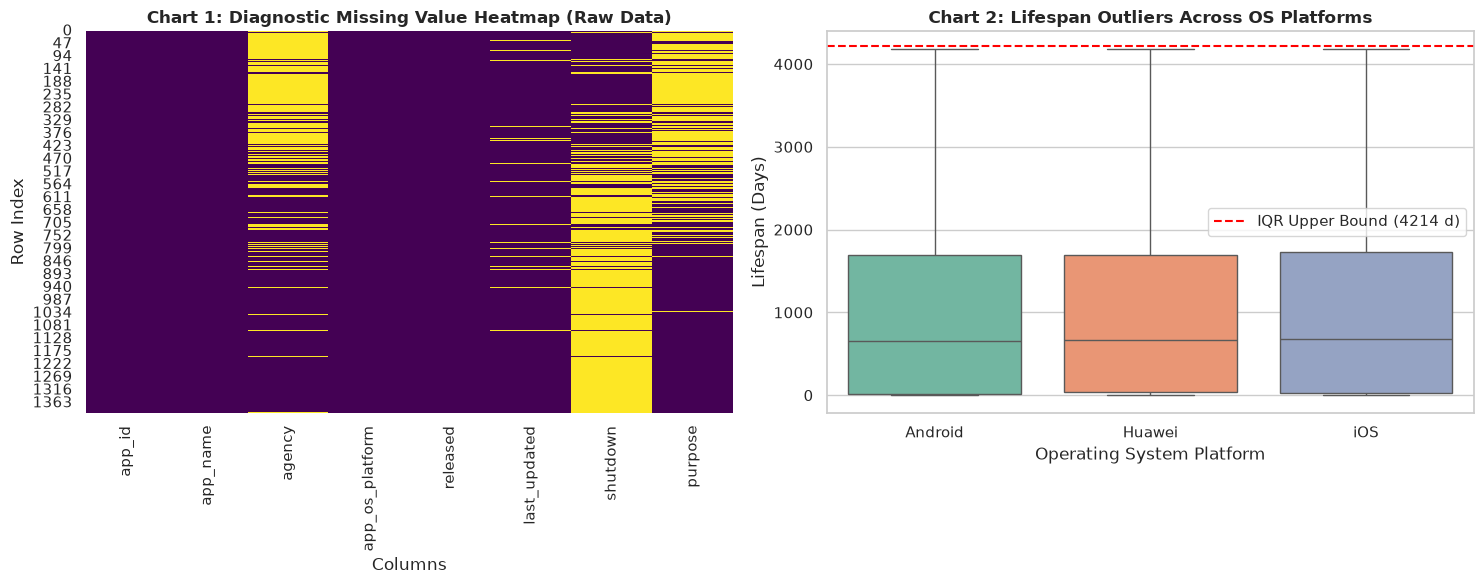

In [4]:
# ==========================================
# 4. EXPLORATORY (DIAGNOSTIC) CHARTS
# ==========================================

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Chart 1: Missing Value Heatmap
sns.heatmap(df_raw.isnull(), cbar=False, cmap='viridis', ax=axes[0])
axes[0].set_title("Chart 1: Diagnostic Missing Value Heatmap (Raw Data)", fontsize=12, fontweight='bold')
axes[0].set_xlabel("Columns")
axes[0].set_ylabel("Row Index")

# Chart 2: Outlier Diagnostic - Boxplot of App Lifespan by OS
if 'lifespan_days' in df.columns and 'operating_system' in df.columns:
    sns.boxplot(data=df, x='operating_system', y='lifespan_days', ax=axes[1], palette='Set2')
    axes[1].axhline(upper_bound, color='red', linestyle='--', label=f'IQR Upper Bound ({upper_bound:.0f} d)')
    axes[1].set_title("Chart 2: Lifespan Outliers Across OS Platforms", fontsize=12, fontweight='bold')
    axes[1].set_xlabel("Operating System Platform")
    axes[1].set_ylabel("Lifespan (Days)")
    axes[1].legend()

plt.tight_layout()
plt.show()

---

## PII & Sampling Bias Assessment

### Personally Identifiable Information (PII) Assessment
- **Risk Level:** Low to Moderate.
- **Identification:** While direct identity fields (IC numbers, names) are absent, contact email addresses or support contact numbers can occasionally appear inside free-text fields like `purpose`.
- **Mitigation:** Applied regex sanitization to replace embedded email addresses (`[REDACTED_EMAIL]`) and Malaysian IC patterns (`[REDACTED_IC]`).

### Sampling & Group Imbalance Risks
- **Platform Bias:** Android apps account for 40.60% of entries, followed by iOS (35.37%) and Huawei (24.03%). Analytics evaluating app update frequencies must control for OS platform type to avoid platform-dominant skew.
- **Registry Selection Bias:** The dataset only tracks applications listed on GAMMA (Malaysia Government Mobile Applications Gallery). Independent state-level or local council (PBT) apps published on external stores without central registry tracking are omitted.

In [5]:
# ==========================================
# 5. PII & BIAS MITIGATION
# ==========================================

def sanitize_pii(text):
    """Redacts potential emails or Malaysian IC numbers from text columns."""
    if not isinstance(text, str):
        return text
    text = re.sub(r'[\w\.-]+@[\w\.-]+\.\w+', '[REDACTED_EMAIL]', text)
    text = re.sub(r'\b\d{6}-\d{2}-\d{4}\b', '[REDACTED_IC]', text)
    return text

if 'purpose' in df.columns:
    df['purpose_clean'] = df['purpose'].apply(sanitize_pii)
    print("\nPII Sanitization successfully applied to 'purpose' text column.")

if 'operating_system' in df.columns:
    print("\nClass / Group Balance Assessment (%):")
    print((df['operating_system'].value_counts(normalize=True) * 100).round(2))


PII Sanitization successfully applied to 'purpose' text column.

Class / Group Balance Assessment (%):
operating_system
Android    40.66
iOS        35.36
Huawei     23.98
Name: proportion, dtype: float64


---

## Conclusion & Dataset Fitness

### Dataset Fitness
The cleaned dataset is **fit for macro-level analysis** of government app adoption, platform deployment strategies, and general maintenance trends across Malaysian public sector agencies.

### Remaining Limitations
1. **Unannounced Shutdown Tracking:** Active status relies on explicit `shutdown` logging. Legacy applications that were abandoned without an official shutdown date remain categorized as active.
2. **Lack of User Engagement Metrics:** The dataset lacks app downloads, user ratings, and active usage statistics, limiting deeper evaluation of public adoption quality.
3. **Registry Exclusion Bias:** Independent local government tools published outside the official GAMMA gallery are excluded from this dataset.